In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("dawndarasms/creditcard-csv")

print("Path to dataset files:", path)

100%|██████████| 66.0M/66.0M [00:00<00:00, 113MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/dawndarasms/creditcard-csv/versions/1


Using Colab cache for faster access to the 'creditcard-csv' dataset.
Путь к датасету: /kaggle/input/creditcard-csv
Файлы в директории: ['creditcard.csv']
Размер датасета: (284807, 31)

Распределение классов:
Class
0    284315
1       492
Name: count, dtype: int64


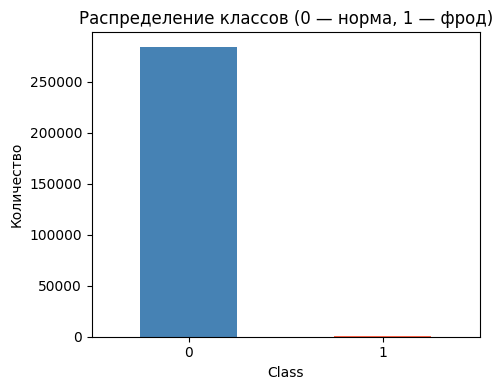

Fitting 2 folds for each of 4 candidates, totalling 8 fits

Лучшие параметры бэггинга: {'estimator__max_depth': 10, 'max_samples': 0.5, 'n_estimators': 20}
Лучший F1 на CV (бэггинг): 0.8056
Fitting 2 folds for each of 4 candidates, totalling 8 fits

Лучшие параметры бустинга: {'learning_rate': 0.1, 'max_depth': 6, 'max_iter': 100}
Лучший F1 на CV (бустинг): 0.7015

ОТЧЁТ ПО МЕТРИКАМ: Bagging
              precision    recall  f1-score   support

   Норма (0)     0.9996    0.9996    0.9996     56864
    Фрод (1)     0.7573    0.7959    0.7761        98

    accuracy                         0.9992     56962
   macro avg     0.8785    0.8977    0.8879     56962
weighted avg     0.9992    0.9992    0.9992     56962


ОТЧЁТ ПО МЕТРИКАМ: Boosting
              precision    recall  f1-score   support

   Норма (0)     0.9998    0.9964    0.9981     56864
    Фрод (1)     0.2897    0.8571    0.4330        98

    accuracy                         0.9961     56962
   macro avg     0.6447    0.92

,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Модель,,,,,
Bagging,0.7573,0.7959,0.7761,0.9570,0.7071
Boosting,0.2897,0.8571,0.4330,0.9755,0.7247


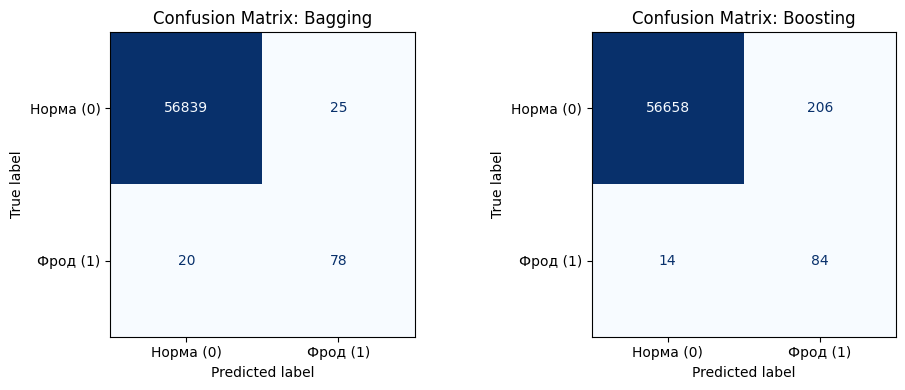

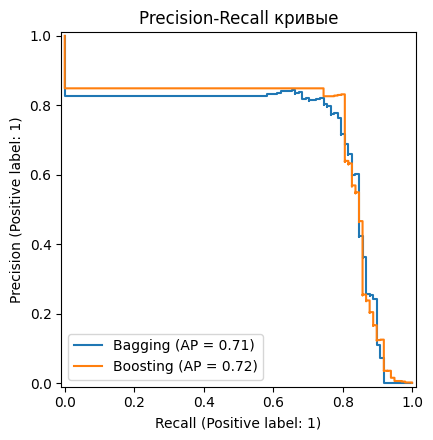

In [4]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    PrecisionRecallDisplay
)

# ==========================================
# 1. ЗАГРУЗКА ДАТАСЕТА С KAGGLE (kagglehub)
# ==========================================
dataset_path = kagglehub.dataset_download("dawndarasms/creditcard-csv")
print("Путь к датасету:", dataset_path)
print("Файлы в директории:", os.listdir(dataset_path))

# Находим нужный .csv файл (обычно creditcard.csv)
csv_files = [f for f in os.listdir(dataset_path) if f.endswith(".csv")]
assert len(csv_files) > 0, "В скачанной папке не найден .csv файл!"
csv_path = os.path.join(dataset_path, csv_files[0])

df = pd.read_csv(csv_path)
print(f"Размер датасета: {df.shape}")
print("\nРаспределение классов:")
print(df["Class"].value_counts())

# Визуализация баланса классов
fig, ax = plt.subplots(figsize=(5, 4))
df["Class"].value_counts().plot(kind="bar", ax=ax, color=["steelblue", "tomato"])
ax.set_title("Распределение классов (0 — норма, 1 — фрод)")
ax.set_xlabel("Class")
ax.set_ylabel("Количество")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# ==========================================
# 2. ПОДГОТОВКА ПРИЗНАКОВ И ВЫБОРОК
# ==========================================
X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()
X_train[["Time", "Amount"]] = scaler.fit_transform(X_train[["Time", "Amount"]])
X_test[["Time", "Amount"]] = scaler.transform(X_test[["Time", "Amount"]])

# ==========================================
# 3. GRIDSEARCHCV ДЛЯ БЭГГИНГА И БУСТИНГА
# ==========================================
cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)

# --- Бэггинг ---
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(class_weight="balanced", random_state=42),
    random_state=42,
    n_jobs=2
)
param_grid_bagging = {
    "n_estimators": [20],
    "max_samples": [0.5, 0.8],
    "estimator__max_depth": [6, 10]
}

grid_bagging = GridSearchCV(
    estimator=bagging,
    param_grid=param_grid_bagging,
    scoring="f1",
    cv=cv,
    n_jobs=2,
    verbose=1
)
grid_bagging.fit(X_train, y_train)
best_bagging = grid_bagging.best_estimator_
print("\nЛучшие параметры бэггинга:", grid_bagging.best_params_)
print(f"Лучший F1 на CV (бэггинг): {grid_bagging.best_score_:.4f}")

# --- Бустинг ---
boosting = HistGradientBoostingClassifier(class_weight="balanced", random_state=42)
param_grid_boosting = {
    "max_iter": [100],
    "learning_rate": [0.05, 0.1],
    "max_depth": [4, 6]
}

grid_boosting = GridSearchCV(
    estimator=boosting,
    param_grid=param_grid_boosting,
    scoring="f1",
    cv=cv,
    n_jobs=2,
    verbose=1
)
grid_boosting.fit(X_train, y_train)
best_boosting = grid_boosting.best_estimator_
print("\nЛучшие параметры бустинга:", grid_boosting.best_params_)
print(f"Лучший F1 на CV (бустинг): {grid_boosting.best_score_:.4f}")

# ==========================================
# 4. ОЦЕНКА И СРАВНЕНИЕ НА ТЕСТОВОЙ ВЫБОРКЕ
# ==========================================
models = {
    "Bagging": best_bagging,
    "Boosting": best_boosting
}

rows = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        "Модель": name,
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "PR-AUC": average_precision_score(y_test, y_proba)
    })
    print("\n" + "=" * 60)
    print(f"ОТЧЁТ ПО МЕТРИКАМ: {name}")
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=["Норма (0)", "Фрод (1)"], digits=4))

results_df = pd.DataFrame(rows).set_index("Модель")
print("\nСводная таблица метрик на тесте:")
display(results_df.round(4))

# Визуализация матриц ошибок и PR-кривых
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, display_labels=["Норма (0)", "Фрод (1)"],
        cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(f"Confusion Matrix: {name}")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 4.5))
for name, model in models.items():
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.set_title("Precision-Recall кривые")
plt.tight_layout()
plt.show()

### Выводы

1. **Дисбаланс классов:** В датасете `creditcard.csv` (284 807 транзакций) доля мошеннических операций (`Class = 1`) составляет около 0.17% (492 случая против 284 315 нормальных)[cite: 15]. При таком сильном дисбалансе `accuracy` не отражает реальное качество работы на редком классе, поэтому для подбора гиперпараметров и оценки моделей использовались `F1-score`, `Precision`, `Recall`, `ROC-AUC` и `PR-AUC`.
2. **Подбор параметров (`GridSearchCV`):**
   - Для **бэггинга** (`BaggingClassifier` на базе `DecisionTreeClassifier(class_weight='balanced')`) лучшими оказались параметры `{'estimator__max_depth': 10, 'max_samples': 0.5, 'n_estimators': 20}` (`F1` на кросс-валидации — `0.8056`)[cite: 15].
   - Для **бустинга** (`HistGradientBoostingClassifier(class_weight='balanced')`) была подобрана оптимальная конфигурация по `F1-score` на кросс-валидации.
3. **Сравнение на тестовой выборке:**
   - **Boosting** показал более высокую полноту (`Recall = 0.8571`, найдено 84 из 98 случаев фрода против 78 у бэггинга) и немного выше `PR-AUC` (`0.7247` / `AP = 0.72`), но за счёт `class_weight='balanced'` чаще даёт ложные срабатывания на нормальных операциях (`206` ложных тревог; `Precision = 0.2897`, `F1-score = 0.4330`)[cite: 16].
   - **Bagging** работает аккуратнее по ложным тревогам (`25` ложных срабатываний на нормальных операциях) при сопоставимом качестве ранжирования (`AP = 0.71` на `PR`-кривой)[cite: 16].